In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import seaborn as sns
import pandas as pd
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import dice, jaccard, hamming
import xarray as xr

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.ExperimentSet import ExperimentSet

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
def fcn_rel_bias(r1, r2):
    """Bias of r2 relative to r1"""
    return 100 * (np.nansum(np.abs(r2)) - np.nansum(np.abs(r1))) / (np.nansum(np.abs(r1)))

def fcn_abs_bias(r1, r2):
    """Bias of r2 relative to r1"""
    return (np.nansum(np.abs(r2)) - np.nansum(np.abs(r1)))

def fcn_MBE(r1, r2):
    """Mean bias error"""
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    return (1/len(r1)) * np.sum(r2 - r1)

def fcn_rel_rmse(r1, r2):
    """RMSE of r2 relative to r1"""
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    return 100 * (np.sum((r2 - r1)**2)**0.5) / (np.sum(r1**2)**0.5)

def fcn_RMSD(r1, r2):
    """Root Mean Squared Difference"""
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    return ((1/len(r1)) * np.sum((r2 - r1)**2))**0.5

def fcn_wasserstein(r1, r2):
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    return wasserstein_distance(np.ravel(r1), np.ravel(r2))

def fcn_pearson_corr(r1, r2):
    cond = np.logical_or(np.logical_not(np.isnan(r1)), np.logical_not(np.isnan(r2)))
    r1 = r1[cond]
    r2 = r2[cond]
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    r1bar = np.mean(r1)
    r2bar = np.mean(r2)
    return (np.sum((r1 - r1bar) * (r2 - r2bar))) / (np.sum((r1 - r1bar)**2)**0.5 * np.sum((r2 - r2bar)**2)**0.5)

def fcn_dice_dissimilarity(r1, r2):
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    r1 = r1 >= 0.3
    r2 = r2 >= 0.3
    return dice(np.ravel(r1), np.ravel(r2))

def fcn_jaccard(r1, r2):
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    r1 = r1 >= 0.3
    r2 = r2 >= 0.3
    return 1 - jaccard(np.ravel(r1), np.ravel(r2))

def fcn_simple_matching_coef(r1, r2):
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    r1 = r1 >= 0.3
    r2 = r2 >= 0.3
    return 1 - hamming(np.ravel(r1), np.ravel(r2))

def compare_extinction(exset, fcn):
    """Compute a scalar value that compares the extinction from each retrieval
    Parameters
    ----------
    exset: ExperimentSet
        Holds all retrievals of interest
    fcn: callable
        Function that takes in two retrieval fields and computes a difference statistic
        relative to the first argument.
    
    Returns
    -------
    dfCompare: pd.DataFrame
        Table comparing the extinction between every retrieval in the set.
    """
    retrieval = []
    reference = []
    data = []
    for r1 in exset.retrievals.values():
        for r2 in exset.retrievals.values():
            retrieval.append(r2.exp_name)
            reference.append(r1.exp_name)
            data.append(fcn(
                r1.get_extinction(0.67, 'cloud'),
                r2.get_extinction(0.67, 'cloud')
            ))
    dfCompare = pd.DataFrame({
        'retrieval': retrieval,
        'reference': reference,
        'data': data
    })
    dfCompare = dfCompare.pivot(index='retrieval', columns='reference', values='data')
    return dfCompare

In [5]:
def compare_extinction_slices(exset, fcn, axis='z', wavelength=0.67, medium='cloud'):
    """Compute a slice-by-slice metric between every pair of retrievals.
    
    Parameters
    ----------
    exset : ExperimentSet
        Holds all retrievals of interest.
    fcn : callable
        Function that takes two extinction slices and returns a scalar metric.
        The second argument is interpreted relative to the first.
    axis : str
        Axis to slice along. Must be one of 'x', 'y', or 'z'.
    wavelength : float
        Retrieval wavelength used to access the extinction field.
    medium : str
        Retrieval medium used to access the extinction field.
    
    Returns
    -------
    dfCompare : pd.DataFrame
        Long-form table with retrieval, reference, dimension, coordinate, and data columns.
    coord_values : np.ndarray
        Coordinate values along the requested axis.
    """
    axis_map = {'x': 0, 'y': 1, 'z': 2}
    if axis not in axis_map:
        raise ValueError(f"axis must be one of {tuple(axis_map)}")

    axis_num = axis_map[axis]
    retrieval = []
    reference = []
    coordinate = []
    dimension = []
    data = []
    coord_values = None

    for r1 in exset.retrievals.values():
        ext_da1 = r1.solvers_retrieval[wavelength].medium[medium].extinction
        for r2 in exset.retrievals.values():
            ext_da2 = r2.solvers_retrieval[wavelength].medium[medium].extinction

            if ext_da1.shape != ext_da2.shape:
                raise ValueError(
                    f"Extinction fields must have the same shape; got {ext_da1.shape} and {ext_da2.shape}."
                )

            if coord_values is None:
                coord_values = ext_da1.coords[axis].values

            for coord_val in coord_values:
                r1_slice = ext_da1.sel({axis: coord_val}).data.copy()
                r2_slice = ext_da2.sel({axis: coord_val}).data.copy()
                retrieval.append(r2.exp_name)
                reference.append(r1.exp_name)
                coordinate.append(float(coord_val))
                dimension.append(axis)
                data.append(fcn(r1_slice, r2_slice))

    dfCompare = pd.DataFrame({
        'retrieval': retrieval,
        'reference': reference,
        'dimension': dimension,
        'coordinate': coordinate,
        'data': data
    })
    return dfCompare, coord_values

In [12]:
def compare_extinction_targets(exset, fcn, T, wavelength=0.67, medium='cloud'):
    """Compute a metric between every pair of retrievals for each target domian size.
    
    Parameters
    ----------
    exset : ExperimentSet
        Holds all retrievals of interest.
    fcn : callable
        Function that takes two extinction slices and returns a scalar metric.
        The second argument is interpreted relative to the first.
    T : list
        Target domain sizes.
    wavelength : float
        Retrieval wavelength used to access the extinction field.
    medium : str
        Retrieval medium used to access the extinction field.
    
    Returns
    -------
    dfCompare : pd.DataFrame
        Long-form table with retrieval, reference, dimension, coordinate, and data columns.

    """


    retrieval = []
    reference = []
    coordinate = []
    data = []

    for r1 in exset.retrievals.values():
        ext_da1 = r1.solvers_retrieval[wavelength].medium[medium].extinction
        xcenter = 0.5 * (np.max(ext_da1.x.data) + np.min(ext_da1.x.data))
        ycenter = 0.5 * (np.max(ext_da1.y.data) + np.min(ext_da1.y.data))
        for r2 in exset.retrievals.values():
            ext_da2 = r2.solvers_retrieval[wavelength].medium[medium].extinction

            if ext_da1.shape != ext_da2.shape:
                raise ValueError(
                    f"Extinction fields must have the same shape; got {ext_da1.shape} and {ext_da2.shape}."
                )

            for t in T:
                xmin = xcenter - t/2
                xmax = xcenter + t/2
                ymin = ycenter - t/2
                ymax = ycenter + t/2
                r1_slice = ext_da1.sel(x=slice(xmin,xmax), y=slice(ymin,ymax)).data.copy()
                r2_slice = ext_da2.sel(x=slice(xmin,xmax), y=slice(ymin,ymax)).data.copy()
                retrieval.append(r2.exp_name)
                reference.append(r1.exp_name)
                coordinate.append(float(t))
                data.append(fcn(r1_slice, r2_slice))

    dfCompare = pd.DataFrame({
        'retrieval': retrieval,
        'reference': reference,
        'coordinate': coordinate,
        'data': data
    })
    return dfCompare

In [13]:
comp_dict = {
    # 'abs_bias':{
    #     'fcn': fcn_abs_bias
    # },
    # 'rel_bias':{
    #     'fcn': fcn_rel_bias
    # },
    'mean_bias_error':{
        'fcn': fcn_MBE
    },
    # 'rel_rmse':{
    #     'fcn': fcn_rel_rmse
    # },
    'root_mean_squared_difference':{
        'fcn': fcn_RMSD
    },
    'wasserstein_distance':{
        'fcn': fcn_wasserstein
    },
    'pearson_correlation':{
        'fcn': fcn_pearson_corr
    },
    # 'dice_dissimilarity':{
    #     'fcn': fcn_dice_dissimilarity
    # },
    'jaccard':{
        'fcn': fcn_jaccard
    },
    'simple_matching_coefficient':{
        'fcn': fcn_simple_matching_coef
    }
}
# tmpdf, tmpi = compare_extinction_slices(exset, fcn_abs_bias, axis='z', wavelength=0.67, medium='cloud')

In [14]:
for fn_name in comp_dict:
    comp_dict[fn_name]['dfCompare'] = compare_extinction(exset, comp_dict[fn_name]['fcn'])
    comp_dict[fn_name]['dfCompareSlice'], _ = compare_extinction_slices(exset, comp_dict[fn_name]['fcn'])
    comp_dict[fn_name]['dfComapreTarget'] = compare_extinction_targets(exset, comp_dict[fn_name]['fcn'], np.arange(0, 17.61, 0.55))

/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_2752788/1372724197.py:40: RuntimeWarning: invalid value encountered in scalar divide
  return (np.sum((r1 - r1bar) * (r2 - r2bar))) / (np.sum((r1 - r1bar)**2)**0.5 * np.sum((r2 - r2bar)**2)**0.5)


In [ ]:
# sublist = ['0p150']
# sublist = ['surf4p0']
# sublist = ['periodic']
sublist = ['unconstrained']
reference = 'default'

for fn_name in comp_dict:
    f, ax = plt.subplots(1, 1, figsize=(7,4))
    slice_df = comp_dict[fn_name]['dfCompareSlice']
    filtered_df = slice_df[slice_df['reference'] == reference]

    for retrieval_name in sublist:
        retrieval_data = filtered_df[filtered_df['retrieval'] == retrieval_name].sort_values('coordinate')
        ax.plot(retrieval_data['data'], retrieval_data['coordinate'], marker='o', label=retrieval_name)
    
    ax.set_xlabel(fn_name)
    ax.set_ylabel('z (km)')
    ax.set_title(f'{fn_name} (reference: {reference})')
    ax.legend()
    ax.grid(alpha=0.3)


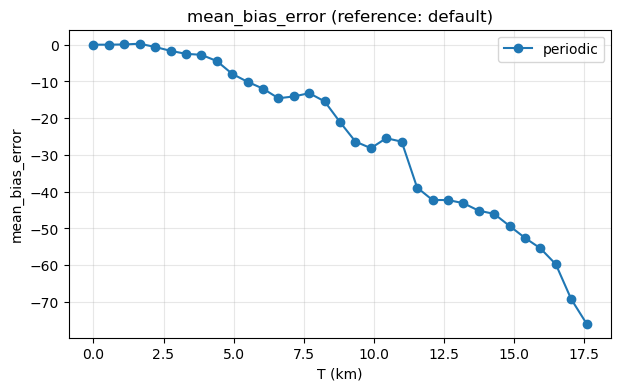

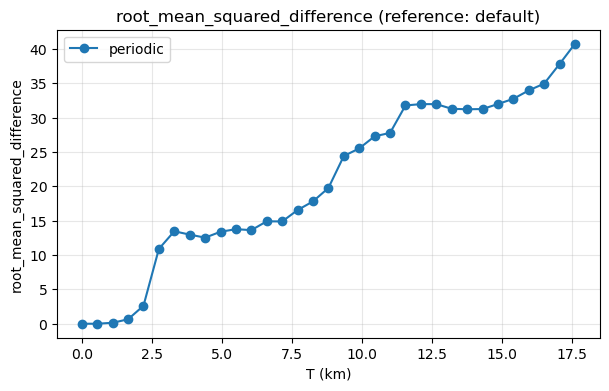

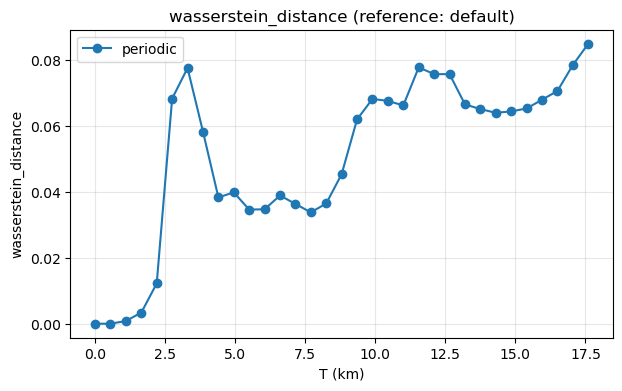

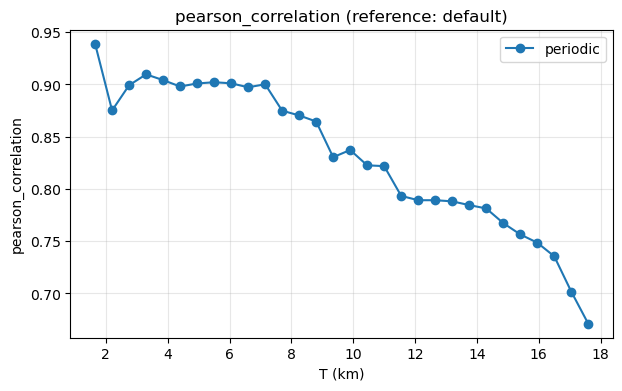

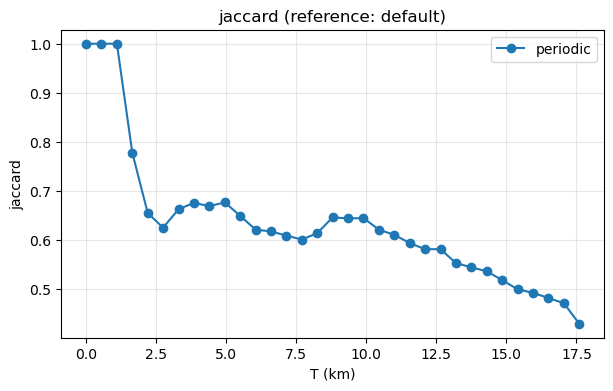

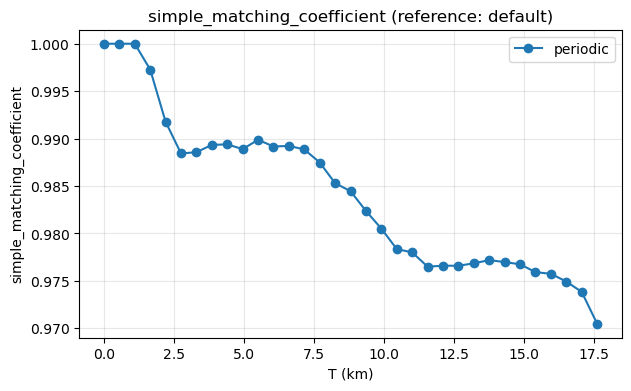

In [15]:
# sublist = ['0p150']
# sublist = ['surf4p0']
sublist = ['periodic']
# sublist = ['unconstrained']
reference = 'default'

for fn_name in comp_dict:
    f, ax = plt.subplots(1, 1, figsize=(7,4))
    slice_df = comp_dict[fn_name]['dfComapreTarget']
    filtered_df = slice_df[slice_df['reference'] == reference]

    for retrieval_name in sublist:
        retrieval_data = filtered_df[filtered_df['retrieval'] == retrieval_name].sort_values('coordinate')
        ax.plot(retrieval_data['coordinate'], retrieval_data['data'], marker='o', label=retrieval_name)
    
    ax.set_ylabel(fn_name)
    ax.set_xlabel('T (km)')
    ax.set_title(f'{fn_name} (reference: {reference})')
    ax.legend()
    ax.grid(alpha=0.3)


In [ ]:
bias = compare_extinction(exset, fcn_rel_bias)
rmse = compare_extinction(exset, fcn_rel_rmse)
emd = compare_extinction(exset, fcn_wasserstein)
pcorr = compare_extinction(exset, fcn_pearson_corr)
dice_coef = compare_extinction(exset, fcn_dice_dissimilarity)
jacc_coef = compare_extinction(exset, fcn_jaccard)

In [ ]:
sublist = ['default', 'periodic', 'unconstrained', '0p150', '0p250']

In [ ]:
f, ax = plt.subplots(3, 2, figsize=(14, 14))
sns.heatmap(bias.loc[sublist, sublist], annot=True, fmt='.0f', cmap='RdBu_r', vmin=-100, vmax=100, linewidth=0.5, ax=ax[0,0])
sns.heatmap(rmse.loc[sublist, sublist], annot=True, fmt='.0f', cmap='viridis', linewidth=0.5, ax=ax[0,1])
sns.heatmap(emd.loc[sublist, sublist], annot=True, fmt='.2f', cmap='viridis', linewidth=0.5, ax=ax[1,0])
sns.heatmap(pcorr.loc[sublist, sublist], annot=True, fmt='.2f', cmap='viridis', linewidth=0.5, ax=ax[1,1])
sns.heatmap(dice_coef.loc[sublist, sublist], annot=True, fmt='.2f', cmap='viridis', linewidth=0.5, ax=ax[2,0])
sns.heatmap(jacc_coef.loc[sublist, sublist], annot=True, fmt='.2f', cmap='viridis', linewidth=0.5, ax=ax[2,1])
ax[0,0].set_title('Relative Bias')
ax[0,1].set_title('Relative RMSE')
ax[1,0].set_title('Wasserstein Distance')
ax[1,1].set_title('Pearson Correlation Coefficient')
ax[2,0].set_title('Dice Dissimilarity')
ax[2,1].set_title('Jaccard Dissimilarity')

In [ ]:
exdf = exset.to_dataframe(0.67, 'cloud', 'extinction')

In [ ]:
sublist = ['default', 'periodic', 'unconstrained']
sns.histplot(exdf.loc[exdf['retrieval_name'].isin(sublist)], x='extinction', hue='retrieval_name', cumulative=True, fill=False, element='step', stat='count', log_scale=(True, False))

In [ ]:
plot_df = exdf[["z", "extinction", "retrieval_name"]].dropna().copy()
z_values = np.sort(plot_df["z"].unique())
# retrieval_names = list(plot_df["retrieval_name"].dropna().unique())
# retrieval_names = ['default', 'periodic']
# retrieval_names = ['default', 'unconstrained']
retrieval_names = ['0p250', 'default', '0p150']

ncols = min(3, len(z_values))
nrows = int(np.ceil(len(z_values) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.8 * nrows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

x_min = plot_df["extinction"].min()
x_max = plot_df["extinction"].max()
bins = np.linspace(x_min, x_max, 40)
palette = sns.color_palette("tab10", n_colors=max(1, len(retrieval_names)))

for ax, z_value in zip(axes, z_values):
    subset = plot_df[plot_df["z"] == z_value]
    for color, retrieval_name in zip(palette, retrieval_names):
        series = subset.loc[subset["retrieval_name"] == retrieval_name, "extinction"]
        if series.empty:
            continue
        sns.histplot(series, bins=bins, stat="count", element="step", fill=False, common_norm=False, ax=ax, color=color, label=retrieval_name, log_scale=(False,True))
    ax.set_title(f"z = {z_value:g}")
    ax.set_xlabel("Extinction")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, title="retrieval_name")

for ax in axes[len(z_values):]:
    ax.set_visible(False)

fig.suptitle("Extinction histograms by altitude and retrieval", y=1.02)
fig.tight_layout()

In [ ]:
def plot_power(cloud, ax, label=None):
    ext = cloud.extinction.data
    ext = ext - np.nanmean(ext)

    nx, ny, nz = ext.shape
    dx = float(cloud.delx.data)
    dy = float(cloud.dely.data)
    dz = 0.100

    F = np.fft.fftn(ext)
    P = np.abs(F) ** 2 / ext.size

    kx = np.fft.fftfreq(nx, d=dx)
    ky = np.fft.fftfreq(ny, d=dy)
    kz = np.fft.fftfreq(nz, d=dz)
    KX, KY, KZ = np.meshgrid(kx, ky, kz, indexing="ij")
    kr = np.sqrt(KX**2 + KY**2 + KZ**2).ravel()
    P = P.ravel()

    bin_edges = np.linspace(0.0, kr.max(), 80)
    psd_sum, _ = np.histogram(kr, bins=bin_edges, weights=P)
    counts, _ = np.histogram(kr, bins=bin_edges)
    k = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    psd_iso = np.divide(psd_sum, counts, out=np.zeros_like(psd_sum), where=counts > 0)
    valid = counts > 0
    wavelength = 1.0 / k[valid]
    order = np.argsort(wavelength)

    ax.loglog(wavelength[order], psd_iso[valid][order], label=label)

In [ ]:
for i, name in enumerate(exset.retrievals.keys()):
    print(f'{i}: {name}')

In [ ]:
ex_list = [13, 1, 4]

f, ax = plt.subplots(1, 1, figsize=(6, 4))
for ie in ex_list:
    r = list(exset.retrievals.values())[ie]
    plot_power(r.solvers_retrieval[0.67].medium['cloud'], ax, label=r.exp_name)
ax.set_xlabel("Wavelength (km)")
ax.set_ylabel("Power spectral density")
ax.set_title("Isotropic PSD of extinction field")
ax.grid(alpha=0.2, which="both")
ax.legend()


In [ ]:
# Directional PSDs: compute and plot directional spectra
def plot_directional_psd(cloud, ax, label=None):
    ext = cloud.extinction.data
    ext = ext - np.nanmean(ext)

    nx, ny, nz = ext.shape
    dx = float(cloud.delx.data)
    dy = float(cloud.dely.data)
    dz = 0.100

    F = np.fft.fftn(ext)
    P = np.abs(F)**2 / ext.size

    # 1D directional PSDs: sum power over the other two axes
    P_kx = np.sum(P, axis=(1,2))
    P_ky = np.sum(P, axis=(0,2))
    P_kz = np.sum(P, axis=(0,1))

    kx = np.fft.fftfreq(nx, d=dx)
    ky = np.fft.fftfreq(ny, d=dy)
    kz = np.fft.fftfreq(nz, d=dz)

    # Only keep positive wavenumbers for wavelength conversion and plotting
    pos_kx = kx > 0
    pos_ky = ky > 0
    pos_kz = kz > 0

    w_kx = 1.0 / kx[pos_kx]; order_kx = np.argsort(w_kx)
    w_ky = 1.0 / ky[pos_ky]; order_ky = np.argsort(w_ky)
    w_kz = 1.0 / kz[pos_kz]; order_kz = np.argsort(w_kz)

    ax[0].loglog(w_kx[order_kx], P_kx[pos_kx][order_kx])
    ax[1].loglog(w_ky[order_ky], P_ky[pos_ky][order_ky])
    ax[2].loglog(w_kz[order_kz], P_kz[pos_kz][order_kz], label=label)

# Example: plot directional PSD for the same retrievals used above
f, ax = plt.subplots(1, 3, figsize=(15, 4))
for ie in ex_list:
    r = list(exset.retrievals.values())[ie]
    plot_directional_psd(r.solvers_retrieval[0.67].medium['cloud'], ax, label=r.exp_name)
ax[0].set_title('PSD — kx (horizontal)')
ax[0].set_xlabel('Wavelength (km)')
ax[1].set_title('PSD — ky (horizontal)')
ax[1].set_xlabel('Wavelength (km)')
ax[2].set_title('PSD — kz (vertical)')
ax[2].set_xlabel('Wavelength (km)')
for a in ax:
    a.grid(alpha=0.2, which='both')
f.tight_layout()
ax[2].legend()